# Signals and the factory cycle

The signals are ratios of Census M3 seasonally adjusted levels: backlog months (unfilled orders over shipments), book-to-bill (new orders over shipments), inventories to shipments, the inventory stage shares, and the materials-to-finished gap, (materials minus finished goods) over total inventories. The gap is the project's primary divergence measure: the alternative difference of share changes is identically twice the change in the early-stage share, because the three stages sum to total inventories.

In [1]:
import sys
sys.path.insert(0, "../src")
import pandas as pd
from factory_cycle.loaders import load_m3_levels, load_g17, load_alfred_vintages
from factory_cycle import signals as sig
pd.set_option("display.width", 140)
m3 = load_m3_levels("../data/staged/m3_levels.parquet")
g17 = load_g17("../data/staged/g17.parquet")
panel = sig.build_signals_panel(m3)


## The panel: one row per month per aggregate

In [2]:
panel.head(8)

,month,aggregate,VS,NO,UO,TI,MI,WI,FI,backlog_months,book_to_bill,inventories_to_shipments,early_stage_share,finished_share,materials_finished_gap,materials_finished_gap_change_12m
0,1992-01-01,MDM,117958.0,NaN,471297.0,242159.0,70311.0,107866.0,63982.0,3.995464,NaN,2.052926,0.735785,0.264215,0.026136,NaN
1,1992-02-01,MDM,119895.0,114535.0,468468.0,241142.0,70042.0,107358.0,63742.0,3.907319,0.955294,2.011277,0.735666,0.264334,0.026126,NaN
2,1992-03-01,MDM,124897.0,120025.0,466222.0,242116.0,70073.0,107662.0,64381.0,3.732852,0.960992,1.938525,0.734090,0.265910,0.023509,NaN
3,1992-04-01,MDM,126174.0,124470.0,467127.0,241520.0,69750.0,107487.0,64283.0,3.702245,0.986495,1.914182,0.733840,0.266160,0.022636,NaN
4,1992-05-01,MDM,127638.0,125822.0,468021.0,240786.0,69786.0,106605.0,64395.0,3.666784,0.985772,1.886476,0.732563,0.267437,0.022389,NaN
5,1992-06-01,MDM,127867.0,122834.0,465647.0,240148.0,69842.0,105792.0,64514.0,3.641651,0.960639,1.878108,0.731357,0.268643,0.022186,NaN
6,1992-07-01,MDM,129589.0,122590.0,461351.0,239228.0,69177.0,105175.0,64876.0,3.560109,0.945991,1.846052,0.728811,0.271189,0.017979,NaN
7,1992-08-01,MDM,127652.0,120411.0,456633.0,240139.0,69682.0,105267.0,65190.0,3.577171,0.943275,1.881200,0.728532,0.271468,0.018706,NaN


## Latest readings

Nondurable goods has no backlog (Census publishes no unfilled orders for nondurables) and its book-to-bill is 1 by construction. Capital goods has no stage inventories.

In [3]:
latest = panel.sort_values('month').groupby('aggregate').tail(1)
latest[['aggregate', 'month', 'backlog_months', 'book_to_bill', 'inventories_to_shipments', 'early_stage_share', 'finished_share', 'materials_finished_gap']]

,aggregate,month,backlog_months,book_to_bill,inventories_to_shipments,early_stage_share,finished_share,materials_finished_gap
833,MNM,2026-09-01,NaN,1.000000,1.102873,0.559873,0.440127,-0.075981
416,MDM,2026-09-01,4.820182,1.026101,1.811805,0.722889,0.277111,0.106413
1250,MTM,2026-09-01,2.429214,1.013154,1.460151,0.661813,0.338187,0.038077
1667,TCG,2026-09-01,10.201332,1.095701,2.428680,NaN,NaN,NaN


## Validation: computed inventories to shipments against the published IS ratio

The published ratio is rounded to two decimals, so agreement to within about 0.005 is exact agreement.

In [4]:
sig.is_crosscheck(m3, ['MTM', 'MDM', 'MNM'])

{'MTM': {'n': 417,
  'max_abs_diff': 0.004981674238031308,
  'mean_abs_diff': 0.0025012593215987355},
 'MDM': {'n': 417,
  'max_abs_diff': 0.004986695050558598,
  'mean_abs_diff': 0.0023288325857689584},
 'MNM': {'n': 417,
  'max_abs_diff': 0.004993144395386118,
  'mean_abs_diff': 0.0025493848753535713}}

## Backlog months over the full span

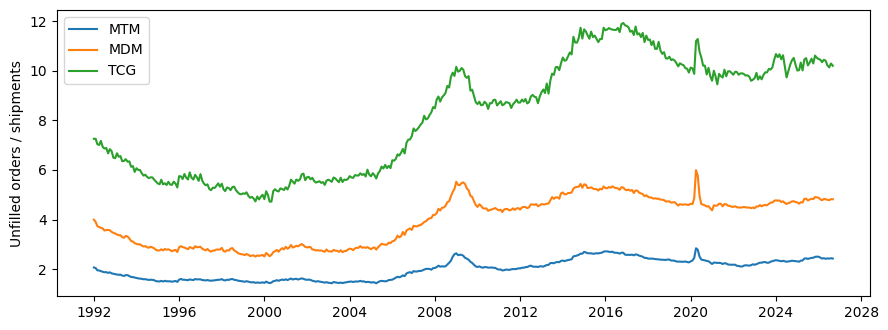

In [5]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 3.4))
for agg in ['MTM', 'MDM', 'TCG']:
    sub = panel[panel['aggregate'] == agg]
    ax.plot(sub['month'], sub['backlog_months'], label=agg)
ax.set_ylabel('Unfilled orders / shipments')
ax.legend()
fig.tight_layout()
plt.show()

## Inventory stage mix, total manufacturing

The early-stage share and the finished share sum to 1. The materials-to-finished gap compares the two ends of the pipeline directly.

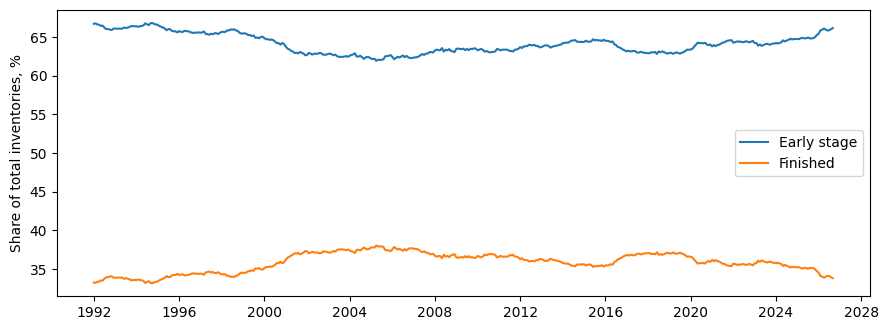

In [6]:
mtm = panel[panel['aggregate'] == 'MTM']
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(mtm['month'], 100 * mtm['early_stage_share'], label='Early stage')
ax.plot(mtm['month'], 100 * mtm['finished_share'], label='Finished')
ax.set_ylabel('Share of total inventories, %')
ax.legend()
fig.tight_layout()
plt.show()